In [75]:
import numpy as np
import pyccl as ccl
import matplotlib.pyplot as plt
import src.simulate as sim

from importlib import reload
reload(sim)

<module 'src.simulate' from '/home/b7009348/CosyMAML/src/simulate.py'>

## Test different IA models impact on data vector
- Are differences in C_ell due to IA model variation signifcant above emulator error? (~ 2-10%)
- Is injection into meta-training sample simple?
- Do we want meta-tasks to vary N(z) and IA model simultaneously or keep IA as a separate case study?
- Current idea is to add A_IA as a parameter to marginalise over, while keeping eta hidden and varying it as part of the meta-tasks


Text(0, 0.5, 'N(z)')

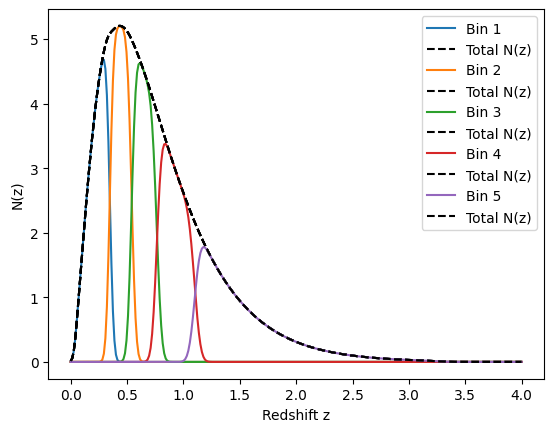

In [61]:
def build_nz_bins(sigma_z, n_bins=5):
    """Build redshift bins and convolve with photo-z errors."""
    # Construct the redshift distribution
    z = np.linspace(0.05, 3.5, 300)

    # Bin the redshift distribution with equal area per bin
    kwargs = {'z0': 0.13, 'alpha': 0.78}
    z_bins, dndz_bins = sim.bin_dndz(n_bins, z, sim.Smail_dndz, **kwargs)

    # Convolve photo-z errors
    dndz_bin_ph = np.zeros((n_bins, len(z)))
    for j in range(n_bins):
        z_ph, dndz_bin_ph[j] = sim.convolve_photoz(
            sigma=sigma_z, 
            zs=z_bins[j], 
            dndz_spec=dndz_bins[j]
        )

    return z_ph, dndz_bin_ph

n_bins=5
z_ph, dndz_bin_ph = build_nz_bins(sigma_z=0.02)

for j in range(n_bins):
    plt.plot(
        z_ph, 
        dndz_bin_ph[j], 
        label=f'Bin {j+1}'
    )
    plt.plot(
        z_ph,
        np.sum(dndz_bin_ph, axis=0),
        color='k',
        label='Total N(z)',
        ls='--'
    )
plt.legend()
plt.xlabel('Redshift z')
plt.ylabel('N(z)')

Mean weighted redshift: 0.7562824717980434


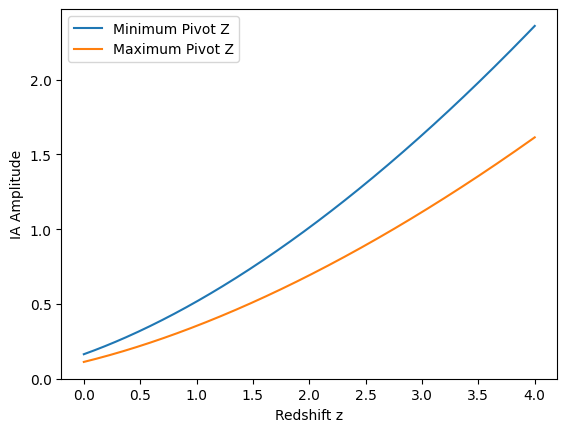

In [ ]:
# Define NLA IA models
def nla_ia(z, a_ia, eta, z0, c=0):
    """Non-linear alignment intrinsic alignment model."""
    return a_ia * ((1 + z) / (1 + z0))**eta # growth factor is applied internally in CCL

n_tasks = 20

z0_range = np.linspace(0.62 - 0.2, 0.62 + 0.2, n_tasks)

A_ia_min = nla_ia(z_ph, a_ia=0.34, eta=1.66, z0=z0_range.min())
A_ia_max = nla_ia(z_ph, a_ia=0.34, eta=1.66, z0=z0_range.max())

plt.plot(z_ph, A_ia_min, label='Minimum Pivot Z')
plt.plot(z_ph, A_ia_max, label='Maximum Pivot Z')
plt.xlabel('Redshift z')
plt.ylabel('IA Amplitude')
plt.legend()

In [66]:
sigma_z_range = np.linspace(0.02, 0.07, n_tasks)

# compute dndz with different photo-z errors
z_ph, dndz_bin_ph_min = build_nz_bins(sigma_z=sigma_z_range.min(), n_bins=n_bins)
z_ph, dndz_bin_ph_max = build_nz_bins(sigma_z=sigma_z_range.max(), n_bins=n_bins)

Text(0.5, 1.0, 'Percentage Difference between IA Models')

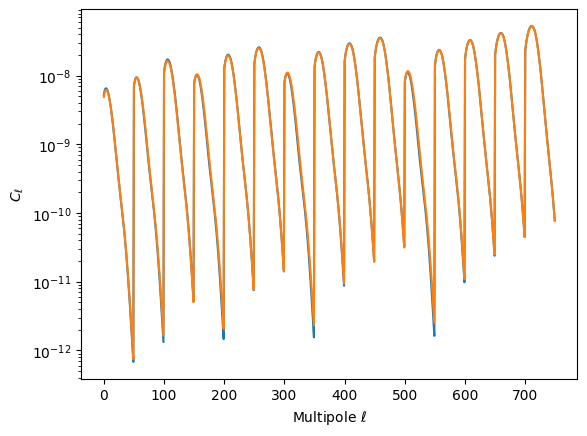

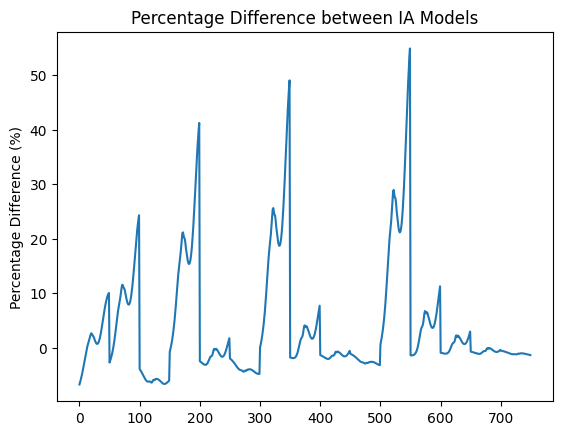

In [67]:
def compute_cl_ia(cosmo, z_ph, ells, dndz_bin_ph, A_ia_model):
    n_bins = dndz_bin_ph.shape[0]
    inds = list(zip(*np.tril_indices(n_bins)))

    c_ells = np.empty((len(inds), len(ells)))
    for i, arg in enumerate(inds):
        j, k = arg
        tracer1 = ccl.WeakLensingTracer(
            cosmo,
            dndz=(z_ph, dndz_bin_ph[j]),
            ia_bias=(z_ph, A_ia_model),
            use_A_ia=True # use conventional IA normalisation with growth factor
        )
        tracer2 = ccl.WeakLensingTracer(
            cosmo,
            dndz=(z_ph, dndz_bin_ph[k]),
            ia_bias=(z_ph, A_ia_model),
            use_A_ia=True # use conventional IA normalisation with growth factor
        )
        c_ells[i,:] = ccl.angular_cl(cosmo, tracer1, tracer2, ells)

    return c_ells.flatten()

# Define a cosmology using CCL
cosmo = ccl.Cosmology(
    Omega_c=0.27,
    Omega_b=0.045,
    h=0.67,
    n_s=0.96,
    sigma8=0.8
)

# Define multipoles
ells = np.geomspace(2, 5000, 50)

# Compute Cls without and with redshift evolution
cl_max_z0 = compute_cl_ia(cosmo, z_ph, ells, dndz_bin_ph_max, A_ia_max)
cl_min_z0 = compute_cl_ia(cosmo, z_ph, ells, dndz_bin_ph_min, A_ia_min)

# Plot the results
plt.semilogy(cl_min_z0, label='NLA IA Minimum Pivot Z')
plt.semilogy(cl_max_z0, label='NLA IA Maximum Pivot Z')
plt.xlabel(r'Multipole $\ell$')
plt.ylabel(r'$C_\ell$')

# Calculate % difference as function of ell
percent_diff = 100 * (cl_max_z0 - cl_min_z0) / cl_min_z0
plt.figure()
plt.plot(percent_diff)
#plt.xlabel(r'Multipole $\ell$')
plt.ylabel('Percentage Difference (%)')
plt.title('Percentage Difference between IA Models')

## Generate a large sample of IA data-vectors
- Use a uniform sampling of IA parameters
- Use a hypercube sampling of cosmology parameters
- Feed to compute via parallelbar

Text(0.5, 1.0, 'Sampled IA Parameter Space')

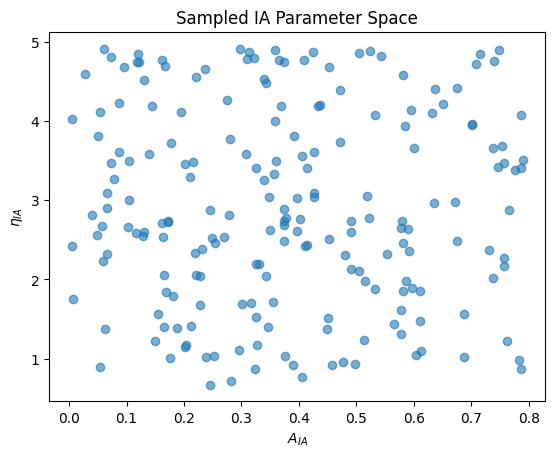

In [ ]:
# # Seed
# np.random.seed(14)

# n_tasks = 200

# # Sample A_IA from DES Y3 constraints
# A_ia_samples = np.random.uniform(low=0, high=0.79, size=n_tasks)
# eta_samples = np.random.uniform(low=0.61, high=4.92, size=n_tasks)

# # Plot parameter points to ensure 2D space coverage
# plt.figure()
# plt.scatter(A_ia_samples, eta_samples, alpha=0.6)
# plt.xlabel(r'$A_{IA}$')
# plt.ylabel(r'$\eta_{IA}$')
# plt.title('Sampled IA Parameter Space')

In [70]:
# Calculate Cls for sampled IA models
cl_samples = np.empty((n_tasks, len(cl_max_z0)))
A_ia_sampled = np.empty((n_tasks, len(z_ph)))
for i in range(n_tasks):
    A_ia_sampled[i] = nla_ia(z_ph, a_ia=0.34, eta=1.66, z0=z0_range[i])
    _, dndz_bin_ph = build_nz_bins(sigma_z=sigma_z_range[i], n_bins=n_bins)
    cl_samples[i] = compute_cl_ia(cosmo, z_ph, ells, dndz_bin_ph, A_ia_sampled[i])

Text(0.5, 1.0, 'Percentage Variation of Sampled IA Cls from Median z0 Sample')

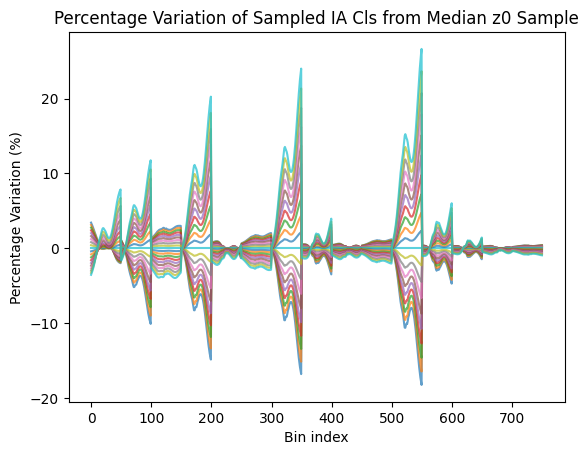

In [71]:
# Calculate % variation in Cls from one another
percent_variations = np.empty((n_tasks, len(cl_max_z0)))
for i in range(len(cl_samples)):
    percent_variations[i] = 100 * (cl_samples[i] - cl_samples[n_tasks//2-1]) / cl_samples[n_tasks//2-1]

# Plot some sampled Cl variations
plt.figure()
for i in range(len(cl_samples)):
    plt.plot(percent_variations[i], alpha=0.7, label=f'Sample {i+1}')
plt.ylabel('Percentage Variation (%)')
plt.xlabel('Bin index')
plt.title('Percentage Variation of Sampled IA Cls from Median z0 Sample')

Computation of IA data vectors is done in *generate_NLA_data.py*

## Test Training MAML model for IA task adaptation

In [ ]:
import h5py as h5
import torch

import src.training as training
import src.models as models

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from scipy.interpolate import interp1d
from copy import deepcopy
from importlib import reload

reload(models)
reload(training)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

Using device: cuda


In [103]:
# Set training tasks and samples numbers
n_tasks =  20
n_samples = 500
batch_size = 5

# Select random subset of tasks for training
np.random.seed(14)
all_indices = np.arange(200)
np.random.shuffle(all_indices)
train_indices = np.sort(all_indices[:n_tasks])
test_index = all_indices[n_tasks]

# Load the data
filepath = '/home/b7009348/CosyMAML/cl_ee_IA_200tasks_1000samples_seed14.h5'
with h5.File(filepath, 'r') as f:
    X_cosmo_train = f['cosmo_params'][train_indices]
    y_cl_train = f['c_ells'][train_indices]

    X_cosmo_test = f['cosmo_params'][test_index]
    y_cl_test = f['c_ells'][test_index]
    A_ia = f['A_ia_samples'][:]
    eta = f['eta_samples'][:]

print('A_ia: {}, eta: {}'.format(A_ia[test_index], eta[test_index]))

# Subsample the data
X_cosmo_train = X_cosmo_train[:, :n_samples, :]
y_cl_train = y_cl_train[:, :n_samples, :]

# Convert to torch tensors
X_cosmo_train = torch.tensor(X_cosmo_train, dtype=torch.float32)
y_cl_train = torch.tensor(y_cl_train, dtype=torch.float32)
print(X_cosmo_train.shape, y_cl_train.shape)

# Construct data loaders
train_dataset = TensorDataset(X_cosmo_train, y_cl_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

A_ia: 0.1288766897379026, eta: 2.547803084455209
torch.Size([20, 500, 5]) torch.Size([20, 500, 750])


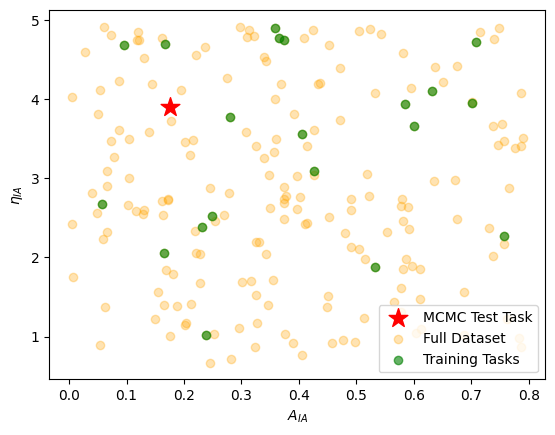

In [106]:
# Check coverage of training data
plt.scatter(0.1747914, 3.8991291, c='red', alpha=1, marker='*', s=200, label='MCMC Test Task')
plt.scatter(A_ia, eta, c='orange', alpha=0.3, label='Full Dataset')
plt.scatter(A_ia[train_indices], eta[train_indices], c='green', alpha=0.6, label='Training Tasks')
plt.xlabel(r'$A_{IA}$')
plt.ylabel(r'$\eta_{IA}$')
plt.legend()

Epoch 10: Meta Loss = 0.042595
Epoch 20: Meta Loss = 0.036143
Epoch 30: Meta Loss = 0.023153
Epoch 40: Meta Loss = 0.011726
Epoch 50: Meta Loss = 0.019397
Epoch 60: Meta Loss = 0.013812
Epoch 70: Meta Loss = 0.013825
Epoch 80: Meta Loss = 0.018841
Epoch 90: Meta Loss = 0.018372
Epoch 100: Meta Loss = 0.004946
Epoch 110: Meta Loss = 0.018692
Epoch 120: Meta Loss = 0.011432
Epoch 130: Meta Loss = 0.010626
Epoch 140: Meta Loss = 0.005956
Epoch 150: Meta Loss = 0.011600
Epoch 160: Meta Loss = 0.007704
Epoch 170: Meta Loss = 0.007991
Epoch 180: Meta Loss = 0.004353
Epoch 190: Meta Loss = 0.003726
Epoch 200: Meta Loss = 0.008338
Training complete.
Best Meta Loss: 0.003726


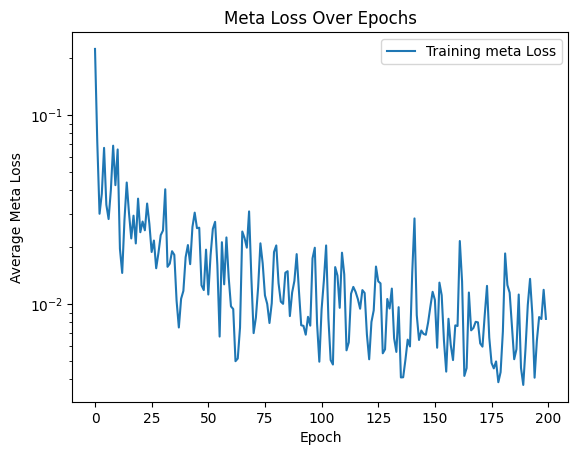

In [105]:
in_size = X_cosmo_train.shape[-1]
out_size = y_cl_train.shape[-1]

# Construct model to train
model = models.FastWeightCNN(
    input_size=in_size,
    latent_dim=(16,16),
    output_size=out_size,
    dropout_rate=0.2
)

# Initialise a MAML trainer
metalearner = training.MetaLearner(
    model=model,
    outer_lr=0.005,
    inner_lr=0.001,
    loss_fn=torch.nn.MSELoss,
    beta1=0.9,
    beta2=0.999,
    epsilon=1e-8,
    seed=14,
    device=device
)

# Train the model
meta_losses = []
epoch = 0
n_epochs = 200
best_loss = np.inf
for i in range(n_epochs):
    epoch_loss = 0.0  # Accumulate loss for reporting purposes
    batch_count = 0   # Keep track of the number of batches
    metalearner.model.train()
    # Iterate through all batches in the dataloader
    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(metalearner.device)  # Move to GPU if available
        y_batch = y_batch.to(metalearner.device)

        # Take logarithm of y_batch
        y_batch = torch.log(y_batch)

        # Split the data into support and query sets
        x_spt, y_spt, x_qry, y_qry = training.support_query_split(
            x_batch, y_batch, spt_frac=0.6
        )

        # Perform one meta update step across the batch
        ##### SCALING APPLIED INTERNALLY #####
        meta_loss = metalearner.meta_train(
            x_spt, y_spt, x_qry, y_qry, inner_steps=5
        )
        
        # Accumulate meta-loss for epoch statistics
        epoch_loss += meta_loss
        batch_count += 1

    # Compute average meta-loss for the epoch
    avg_meta_loss = epoch_loss / batch_count
    meta_losses.append(avg_meta_loss)
    epoch += 1

    if epoch % 10 == 0:
        print(f'Epoch {epoch}: Meta Loss = {avg_meta_loss:.6f}')

    if avg_meta_loss < best_loss:
        best_loss = avg_meta_loss
        torch.save(metalearner.model.state_dict(), 
                   'weights_ia_maml_{}tasks_{}samples_{}batch.pth'.format(
                    n_tasks, n_samples, batch_size
                )
        )

print("Training complete.")
print(f'Best Meta Loss: {best_loss:.6f}')

# Plot the meta-loss over epochs
plt.semilogy(meta_losses, label='Training meta Loss')
plt.xlabel('Epoch')
plt.ylabel('Average Meta Loss')
plt.title('Meta Loss Over Epochs')
plt.legend()

Epoch [20/200], Loss: 0.118307
Epoch [40/200], Loss: 0.033800
Epoch [60/200], Loss: 0.019957
Epoch [80/200], Loss: 0.013918
Epoch [100/200], Loss: 0.010191
Epoch [120/200], Loss: 0.008495
Epoch [140/200], Loss: 0.007774
Epoch [160/200], Loss: 0.007330
Epoch [180/200], Loss: 0.006822
Epoch [200/200], Loss: 0.006437


Text(0, 0.5, 'Training Loss')

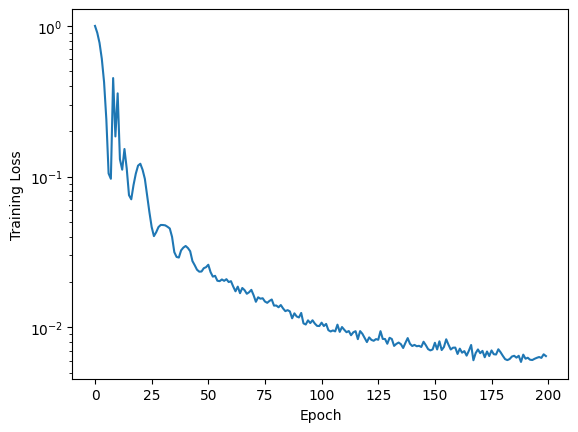

In [107]:
# Train a standard model for comparison
standard_model = models.FastWeightCNN(
    input_size=in_size,
    latent_dim=(16,16),
    output_size=out_size,
    dropout_rate=0.2
)   

standard_model.to(device)
optimizer = torch.optim.Adam(standard_model.parameters(), lr=0.001)

# Scale the data
ScalerX = training.TorchStandardScaler()
ScalerY = training.TorchStandardScaler()
X_train_scaled = ScalerX.fit_transform(X_cosmo_train[0])
y_train_scaled = ScalerY.fit_transform(torch.log(y_cl_train[0]))

# Train only on 1 task
losses = []
for epoch in range(200):
    # Forward pass
    optimizer.zero_grad()
    y_pred = standard_model(X_train_scaled.to(device))
    loss = torch.nn.MSELoss()(y_pred, y_train_scaled.to(device))
    
    # Backward pass and optimization
    loss.backward()
    optimizer.step()
    
    if (epoch+1) % 20 == 0:
        print(f'Epoch [{epoch+1}/200], Loss: {loss.item():.6f}')

    losses.append(loss.item())

original_model = deepcopy(standard_model.state_dict())

plt.semilogy(losses)
plt.xlabel('Epoch')
plt.ylabel('Training Loss')

In [117]:
n_finetune = 100

# Split test data into fine-tuning and evaluation sets
X_finetune, X_eval, y_finetune, y_eval = train_test_split(X_cosmo_test, y_cl_test, train_size=n_finetune, random_state=14)

print(X_finetune.shape, y_finetune.shape, X_eval.shape, y_eval.shape)

# convert to torch tensors
X_finetune = torch.tensor(X_finetune, dtype=torch.float32).to(device)
y_finetune = torch.tensor(y_finetune, dtype=torch.float32).to(device)
X_eval = torch.tensor(X_eval, dtype=torch.float32).to(device)
y_eval = torch.tensor(y_eval, dtype=torch.float32).to(device)

# Scale the data
y_finetune = torch.log(y_finetune)
y_eval = torch.log(y_eval)

ScalerY = training.TorchStandardScaler()
y_finetune = ScalerY.fit_transform(y_finetune)
y_eval = ScalerY.transform(y_eval)

ScalerX = training.TorchStandardScaler()
X_finetune = ScalerX.fit_transform(X_finetune)
X_eval = ScalerX.transform(X_eval)

finetune_dataset = TensorDataset(X_finetune, y_finetune)
finetune_loader = DataLoader(finetune_dataset, batch_size=n_samples, shuffle=True)

eval_dataset = TensorDataset(X_eval, y_eval)
eval_loader = DataLoader(eval_dataset, batch_size=n_samples-n_finetune, shuffle=False)

(100, 5) (100, 750) (900, 5) (900, 750)


In [118]:
task_weights, maml_losses = metalearner.finetune(X_finetune, y_finetune, adapt_steps=64)

In [119]:
# finetune standard model
standard_model.load_state_dict(original_model)
standard_losses = training.finetune_pretrained(
    model=standard_model,
    n_epochs=64,
    train_loader = finetune_loader,
    device=device
)

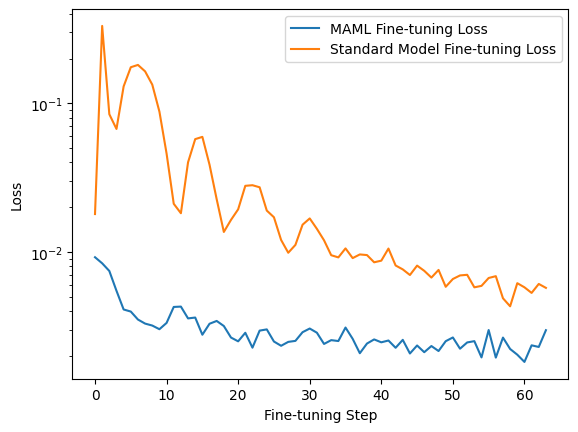

In [120]:
# Plot losses
plt.semilogy(maml_losses, label='MAML Fine-tuning Loss')
plt.semilogy(standard_losses, label='Standard Model Fine-tuning Loss')
plt.xlabel('Fine-tuning Step')
plt.ylabel('Loss')
plt.legend()

In [121]:
############# MAML TRAINING #############
# Construct empty tensor to store 
metalearner.model.eval()
y_pred = torch.tensor([]).to(device)
for X_batch, y_batch in eval_loader:
    with torch.no_grad(): # don't compute gradients during inference
        y_pred_batch = metalearner.model(X_batch, params=task_weights)
        y_pred = torch.cat((y_pred, y_pred_batch), dim=0)

# Inverse transform the data
y_pred = ScalerY.inverse_transform(y_pred)
y_test = ScalerY.inverse_transform(y_eval)

# Detach and convert to numpy
y_pred_np = y_pred.cpu().numpy()
y_test_np = y_test.cpu().numpy()

# Exponentiate the data
y_pred_maml = np.exp(y_pred_np)
y_test_maml = np.exp(y_test_np)

############# STANDARD MODEL TRAINING #############
standard_model.eval()
y_pred = torch.tensor([]).to(device)
for X_batch, y_batch in eval_loader:
    with torch.no_grad(): # don't compute gradients during inference
        y_pred_batch = standard_model(X_batch)
        y_pred = torch.cat((y_pred, y_pred_batch), dim=0)

# Inverse transform the data
y_pred = ScalerY.inverse_transform(y_pred)
y_test = ScalerY.inverse_transform(y_eval)

# Detach and convert to numpy
y_pred_np = y_pred.cpu().numpy()
y_test_np = y_test.cpu().numpy()

# Exponentiate the data
y_pred_standard = np.exp(y_pred_np)
y_test_standard = np.exp(y_test_np)

MAML MAPE: 2.2824268
MAML XAPE: 7.2656264
MAML Failure Rate: 0.008888888888888889
Standard Model MAPE: 3.8470225
Standard Model XAPE: 19.55194
Standard Model Failure Rate: 0.2633333333333333


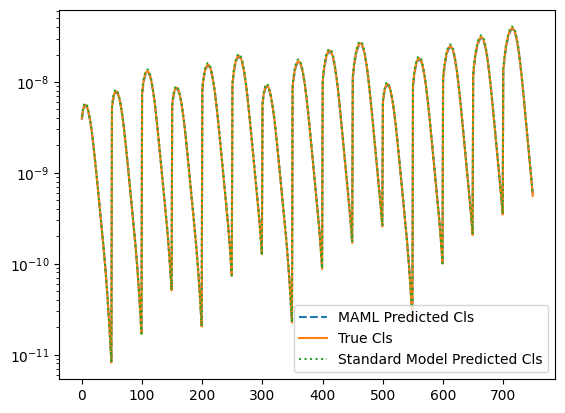

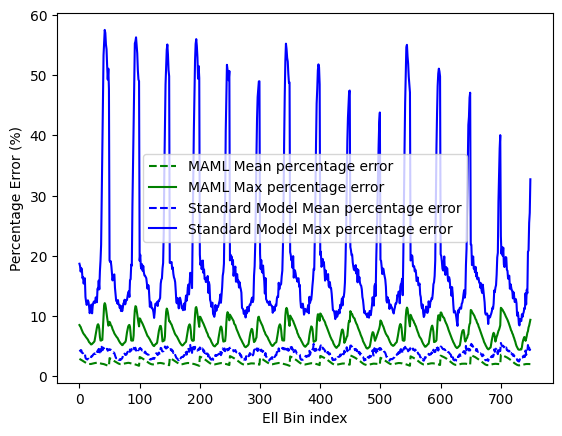

In [122]:
# Plot predictions vs true values for first test sample
plt.figure()
plt.semilogy(y_pred_maml[0], label='MAML Predicted Cls', ls='--')
plt.semilogy(y_test_maml[0], label='True Cls')
plt.semilogy(y_pred_standard[0], label='Standard Model Predicted Cls', ls=':')
plt.legend()

# Compute mean absolute percentage error along the test set
apes = np.abs((y_test_maml - y_pred_maml) / y_test_maml) * 100
ell_ape = np.mean(apes, axis=1)
maml_mape = np.mean(apes, axis=0)
maml_xape = np.max(apes, axis=0)
maml_frate = len(ell_ape[ell_ape > 5]) / len(ell_ape)

# 
apes = np.abs((y_test_standard - y_pred_standard) / y_test_standard) * 100
ell_ape = np.mean(apes, axis=1)
standard_mape = np.mean(apes, axis=0)
standard_xape = np.max(apes, axis=0)
standard_frate = len(ell_ape[ell_ape > 5]) / len(ell_ape)

# Plot MAPE and XAPE
plt.figure()
plt.plot(maml_mape, c='g', ls='--', label='MAML Mean percentage error')
plt.plot(maml_xape, c='g', ls='-', label='MAML Max percentage error')
plt.plot(standard_mape, c='b', ls='--', label='Standard Model Mean percentage error')
plt.plot(standard_xape, c='b', ls='-', label='Standard Model Max percentage error')
plt.xlabel('Ell Bin index')
plt.ylabel('Percentage Error (%)')
plt.legend()

print('MAML MAPE:', np.mean(maml_mape))
print('MAML XAPE:', np.mean(maml_xape))
print('MAML Failure Rate:', maml_frate)

print('Standard Model MAPE:', np.mean(standard_mape))
print('Standard Model XAPE:', np.mean(standard_xape))
print('Standard Model Failure Rate:', standard_frate)